# Entrainement de modèles de classification textuelle

Nous allons voir aujourd'hui comment entrainer des classifieurs textuels, en utilisant des embeddings de mots pour représenter le contenu d'un texte, avec trois méthodes différentes:

1. A partir de représentations
précalculées (statiques comme word2vec, glove).
3. En fine-tunant des modèles contextuels pré-entrainés (type Bert/GPT).
3. En fine-tunant de manière efficace, avec une méthode PEFT (type LoRA, adapters)
4. En testant un petit modèle génératif en zéro-shot

Nous prendrons comme exemple de tâches la classification de sentiments, avec le jeu de données IMDB https://huggingface.co/datasets/stanfordnlp/imdb
  </p>
</div>


# 1. A partir d'embeddings statiques précalculés






On part d'embeddings pré-calculés, ici glove, pour simplifier : un vecteur est fourni pour chaque token du vocabulaire.
On pourrait aussi utiliser un *text embedding model*, MistralAI embeddings par exemple, qui peut prendre un texte en entrée et fournit sa représentation

(cf d'autres exemples de possibilités sur https://docs.langchain.com/oss/javascript/integrations/text_embedding)

In [1]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 17.5 MB/s  0:00:01


In [2]:
import gensim
from tqdm import tqdm

In [3]:
# small glove
import gensim.downloader as api
model = api.load("glove-wiki-gigaword-100") #50, 100, 200, 300

[==================================================] 100.0% 128.1/128.1MB downloaded


In [ ]:
vocabulary = model.key_to_index
print(len(vocabulary))

In [4]:
import numpy as np
import string
punct_remove = str.maketrans('', '',string.punctuation)

In [5]:
# exemple de fonction d'encodage de phrase = moyenne des embeddings des mots
def encode(sentence,model):
  vocabulary = set(model.key_to_index)
  words = sentence.lower().translate(punct_remove)
  words = words.split()
  vector = model[[word for word in words if word in vocabulary]].mean(axis=0)
  return vector


In [6]:
%timeit encode("This is a very short test.",model)

30.3 ms ± 1.62 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


## Le jeu de données

On va considérer l'analyse de "sentiment", sur des critiques de films issus du site IMDB.

https://huggingface.co/datasets/stanfordnlp/imdb





In [7]:
# lib Huggingface qui définit le format des jeux de données utilisables par la lib transformers
!pip install datasets

In [8]:
from datasets import load_dataset
import pandas as pds

In [10]:
# on va seulement entrainer/tester sur une partie du train pour aller plus vite
# sur colab: lettre "stanfordnlp/imdb" à la place
ds = load_dataset("stanfordnlp/imdb",split="train")
# on ne touche pas au "vrai" test
ds = ds.train_test_split(train_size=0.04,test_size=0.02)
dataset_train = ds["train"]
dataset_test = ds["test"]

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [11]:
# regardez ce qui est contenu dans les instances
dataset_train[0]

{'text': 'Philip. K. Dickian movie. And a decent one for that matter. Better than the Paycheck (Woo) and that abomination called Minority Report (Spielberg). But lets face it, the twisting and cheesing ending was a bit too much for me. Half way through the movie I already started to fear about such kind of ending, and I was regrettably right. But that does not mean that the film is not worth its time. No, not at all. First half (as already many here have commented) is awesome. There are some parts where you start to doubt whether the director intended to convey the message that showmanship is highly important thing in the future (we will do such kind on corny sf things because we CAN) or is it simply over combining. But the paranoia is there and feeling "out of joint" also. Good one.',
 'label': 0}

## Encodage des données

Il faut maintenant encoder les instances du jeu de données pour avoir un ensemble de vecteurs des phrases, et les labels associés

**Ecrire la fonction suivante qui doit renvoyer 2 listes (ou vecteurs): 1) de vecteur des phrases 2) des labels correspondants**

In [25]:
# doit retourner une liste de vecteurs, et une liste de labels correspondants
# correction
def encode_train(instances,model):
  vectors = []
  labels = []

  for instance in instances:
    vec = encode(instance['text'], model)

    vectors.append(vec)
    labels.append(instance['label'])

  return vectors, labels

In [26]:
X, y = encode_train(dataset_train,model)

## Entraînement d'un modèle simple

**Vous pouvez maintenant essayer d'entrainer un modèle simple, par exemple une régression logistique ou un MLP avec la librairie scikit-learn, et les évaluer sur les sous-ensembles train et test**


https://scikit-learn.org/1.5/modules/generated/sklearn.linear_model.LogisticRegression.html


https://scikit-learn.org/1.5/modules/generated/sklearn.neural_network.MLPClassifier.html#sklearn.neural_network.MLPClassifier

In [28]:
# Entrainement
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

# logistic regression
clf_lr = LogisticRegression(max_iter=1000)
clf_lr.fit(X, y)
print("accuracy train régression logistique:",clf_lr.score(X,y))
# MLP
clf = MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42)
clf.fit(X, y)
print("accuracy train MLP:",clf.score(X,y))

accuracy train régression logistique: 0.796
accuracy train MLP: 0.861


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [29]:
X_val, y_val = encode_train(dataset_test,model)
y_predicted_val = clf.predict(X_val)

# Evaluate the model's performance on the validation set.
print("\n accuracy test MLP:",clf.score(X_val,y_val))


 accuracy test MLP: 0.778


# 2. Fine-tuning d'un modèle contextuel préentrainé

Cette fois on va continuer l'entrainement d'un modèle préentrainé, sur nos données spécifiques, en utilisant une librairie dédiée, huggingface, qui gère tout depuis la tokenization, entrainement et prédiction.

▶▶ **Dans cette partie tout le code est déjà fonctionnel (sauf pour faire les prédictions sur le test), mais vous devez trouver les meilleurs choix de paramètres**

In [30]:
!pip install evaluate

In [31]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [32]:
import transformers
import evaluate
from transformers import AutoModelForSequenceClassification, AutoTokenizer
from transformers import AutoModelForTokenClassification

In [33]:
# sur colab, bien choisir un GPU/TPU dans le runtime ("Execution/modifier le type d'execution")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [34]:
# plus prudent avec un petit modele, mais vous pouvez essayer avec bert-base-uncased aussi
base_model = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(base_model)
model = AutoModelForSequenceClassification.from_pretrained(base_model)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Différentes options peuvent être testées pour la tokenization.
**Regardez la doc du tokenizer pour éventuellement changer la stratégie de padding et de troncation, et dites si vous voyez des changements de résultats expérimentaux**

In [35]:
# c'est ici qu'on définit ce qui sera effectivement passé en entrée du modèle à partir des instances du dataset
def tokenize_function(examples):
    return tokenizer(examples["text"], padding="max_length", truncation=True)


tokenized_train_datasets = dataset_train.map(tokenize_function, batched=True)
tokenized_test_datasets = dataset_test.map(tokenize_function, batched=True)

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Huggingface permet de définir une boucle d'entrainement à partir de certains paramètres de configuration.

Voici une base, **vous devez tester des réglages différents**

https://huggingface.co/docs/transformers/main_classes/trainer



In [36]:
from transformers import TrainingArguments, Trainer
training_args = TrainingArguments(output_dir="test_trainer",
                                  #no_cuda=False, # True sur ordi perso sans bon GPU
                                  per_device_train_batch_size=8,
                                  eval_strategy="epoch",
                                  report_to="none",
                                  num_train_epochs=1)

In [37]:
# définition de la métrique d'éval
# NE RIEN MODIFIER ICI

# necessary for evaluation during training
metric = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)

In [38]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train_datasets,
    eval_dataset=tokenized_test_datasets,
    compute_metrics=compute_metrics,
)

In [39]:
# necessary on colab -> NE RIEN MODIFIER ICI
# Tell the Trainer to not pin memory / caused by having the data already on GPU
training_args.dataloader_pin_memory = False

res = trainer.train()
print(res)

Epoch,Training Loss,Validation Loss,Accuracy
1,No log,0.305530,0.878000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=125, training_loss=0.4331611328125, metrics={'train_runtime': 61.4989, 'train_samples_per_second': 16.26, 'train_steps_per_second': 2.033, 'total_flos': 132467398656000.0, 'train_loss': 0.4331611328125, 'epoch': 1.0})


In [40]:
# test predictions sur un exemple
inputs = tokenizer("This movie was so bad it was almost good.", return_tensors="pt").to(device)
outputs = model(**inputs)
# get the normalized scores
list(nn.Softmax(dim=1)(outputs.logits).detach().cpu().numpy()[0])

[np.float32(0.94404685), np.float32(0.055953156)]

In [41]:
# get the most likely class
np.argmax(outputs.logits.detach().cpu(),axis=-1)

tensor([0])

On peut regarder les prédictions du modèles, et les scores assignées à chaque classe pour chaque instance, en utilisant la méthode trainer.predict, sur des inputs tokenisés

In [42]:
# à compléter
input_test = tokenized_test_datasets
predictions = trainer.predict(input_test)

In [43]:
predictions.metrics

{'test_loss': 0.3055296838283539,
 'test_accuracy': 0.878,
 'test_runtime': 8.5546,
 'test_samples_per_second': 58.448,
 'test_steps_per_second': 7.364}

In [44]:
predictions.predictions.shape

(500, 2)

In [45]:
# profitons en pour jeter un oeil aux probabilités de classifications
torch_logits = torch.from_numpy(predictions.predictions)
probabilities_scores = F.softmax(torch_logits,dim=1).numpy()

(array([[204.,  22.,   6.,   3.,   7.,   5.,   4.,   3.,   6.,   5.,   0.,
           0.,   7.,   7.,   4.,   6.,  11.,  13.,  19., 168.],
        [168.,  19.,  13.,  11.,   6.,   4.,   7.,   7.,   0.,   0.,   5.,
           6.,   3.,   4.,   5.,   7.,   3.,   6.,  22., 204.]]),
 array([0.03301346, 0.07971211, 0.12641077, 0.17310941, 0.21980807,
        0.26650673, 0.31320536, 0.35990402, 0.40660268, 0.45330134,
        0.5       , 0.54669863, 0.59339726, 0.64009595, 0.68679458,
        0.73349327, 0.7801919 , 0.82689053, 0.87358922, 0.92028785,
        0.96698654]),
 <a list of 2 BarContainer objects>)

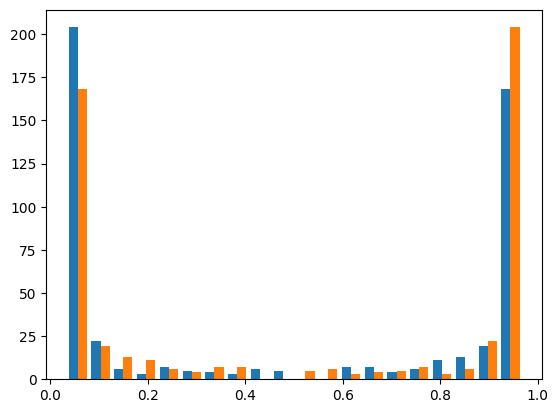

In [46]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.hist(probabilities_scores,20)

**Que peut-on dire des probablités des prédictions du modèle ?**

## 3. Utiliser des méthodes PEFT

Fine-tunez un modèle plus large, par exemple BERT, mais en utilisant la méthode LoRA pour réduire le nombre de paramètres à entraîner.


Plus précisément, on va d'abord fine-tuner BERT, puis continuer le FT avec LoRA, afin de voir les résultats initiaux et comment appliquer LoRA.
On testera ensuite d'autres variantes.



LoRA doc: https://huggingface.co/docs/peft/package_reference/lora

**Etapes à suivre**

Fine-tuning de BERT :
* charger le modèle (BERT),
* l'entraîner
* afficher l'accuracy sur le test

Ajout de LoRA :
* afficher le modèle pour voir le nom donné aux modules (on applique LoRA au moins aux modules : key, query, value ; le reste est frozen)
* définir la config LoRA
* récupérer le modèle LoRA à partir du modèle et de la config
* afficher les couches ainsi que leur taille, avant et après avoir appliqué LoRA
* on garde les même training_args qu'avant
* entraîner puis afficher l'accuracy sur le test
* afficher le nombre de trainable parameters du modèle LoRA

Tests d'hyper-paramètres :
* tester 2 valeurs différentes pour le rang des matrices LoRA : quelles différences ?
* tester l'ajout des couches 'dense' dans LoRA : quelles différences ?


In [47]:
# nécessaire sur colab (11/2026)
!pip install -U torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 24.5 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [48]:
from peft import LoraModel, LoraConfig, get_peft_model

## Finetuning de BERT

In [49]:
# 1. Chargement du modèle BERT et de son tokenizer
bert_model_name = "bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(bert_model_name)
bert_model = AutoModelForSequenceClassification.from_pretrained(bert_model_name, num_labels=2)

# 2. Tokenisation adaptée à BERT
def tokenize_bert(examples):
    return bert_tokenizer(examples["text"], padding="max_length", truncation=True)

tokenized_train_bert = dataset_train.map(tokenize_bert, batched=True)
tokenized_test_bert = dataset_test.map(tokenize_bert, batched=True)

# 3. Entraînement (en réutilisant les mêmes training_args et compute_metrics)
trainer_bert = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=tokenized_train_bert,
    eval_dataset=tokenized_test_bert,
    compute_metrics=compute_metrics,
)

trainer_bert.train()

# 4. Affichage de l'accuracy sur le test
preds_bert = trainer_bert.predict(tokenized_test_bert)
print("Accuracy BERT FT :", preds_bert.metrics["test_accuracy"])

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy
1,No log,0.264633,0.906000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Accuracy BERT FT : 0.906


## Ajout de LoRA

In [50]:
# 1. Afficher l'architecture pour vérifier le nom des modules (on y voit query, key, value, dense)
print(bert_model)

# 2. Définir la configuration LoRA
lora_config = LoraConfig(
    task_type="SEQ_CLS",               # Classification de séquences
    r=8,                               # Rang des matrices LoRA
    lora_alpha=16,                     # Facteur d'échelle (souvent 2 * r)
    lora_dropout=0.1,
    target_modules=["query", "key", "value"] # Modules ciblés demandés dans l'énoncé
)

# 3. Créer le modèle LoRA (attention au nom de variable : lora_model, réutilisé plus bas avec .unload())
lora_model = get_peft_model(bert_model, lora_config)

# 4. Afficher l'architecture après LoRA et le nombre de paramètres entraînables
print(lora_model)
lora_model.print_trainable_parameters()

# 5. Entraîner et évaluer le modèle LoRA
trainer_lora = Trainer(
    model=lora_model,
    args=training_args,
    train_dataset=tokenized_train_bert,
    eval_dataset=tokenized_test_bert,
    compute_metrics=compute_metrics,
)

trainer_lora.train()

preds_lora = trainer_lora.predict(tokenized_test_bert)
print("Accuracy BERT FT + LoRA :", preds_lora.metrics["test_accuracy"])

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,),

W1112 13:20:44.238000 295 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


PeftModelForSequenceClassification(
  (base_model): LoraModel(
    (model): BertForSequenceClassification(
      (bert): BertModel(
        (embeddings): BertEmbeddings(
          (word_embeddings): Embedding(30522, 768, padding_idx=0)
          (position_embeddings): Embedding(512, 768)
          (token_type_embeddings): Embedding(2, 768)
          (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (encoder): BertEncoder(
          (layer): ModuleList(
            (0-11): 12 x BertLayer(
              (attention): BertAttention(
                (self): BertSelfAttention(
                  (query): lora.Linear(
                    (base_layer): Linear(in_features=768, out_features=768, bias=True)
                    (lora_dropout): ModuleDict(
                      (default): Dropout(p=0.1, inplace=False)
                    )
                    (lora_A): ModuleDict(
                      (

Epoch,Training Loss,Validation Loss,Accuracy
1,No log,0.274034,0.910000


Accuracy BERT FT + LoRA : 0.91


## Tests d'hyper-paramètres

Pour enlever le modèle Lora du modèle d'origine pour pouvoir tester d'autres paramètres:

In [51]:
lora_model.unload()

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,),

### Test du LoRA BERT sans FT initial

Au-dessus on a ajouté Lora par dessus le BERT déjà fine-tuné, pour voir les résultats de BERT, et observer comment ajouter Lora au modèle.

Le vrai cas d'usage est de ne pas fine-tuner le modèle préentrainté, mais seulement utiliser Lora pour le fine-tuning.

C'est ce que vous allez faire ici, en rechargeant le modèle de base.

Comparez les résultats: BERT FT, BERT FT+Lora, BERT + Lora

In [ ]:
## Fine tuning BERT with LoRA

In [61]:


# 1. Recharger le modèle de base vierge
fresh_bert = AutoModelForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2)

# 2. Configurer et appliquer LoRA
lora_config = LoraConfig(
    task_type="SEQ_CLS",
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=["query", "key", "value"]
)
lora_only_model = get_peft_model(fresh_bert, lora_config)
lora_only_model.print_trainable_parameters()

# 3. Entraîner le modèle avec le Trainer
trainer_lora_only = Trainer(
    model=lora_only_model,
    args=training_args,
    train_dataset=tokenized_train_bert,
    eval_dataset=tokenized_test_bert,
    compute_metrics=compute_metrics,
)

trainer_lora_only.train()


# Évaluation sur le jeu de test
preds_lora_only = trainer_lora_only.predict(tokenized_test_bert)
acc_bert_lora = preds_lora_only.metrics["test_accuracy"]

# Comparaison des 3 approches
print(f"1. BERT FT (complet)      : {preds_bert.metrics['test_accuracy']:.4f}")
print(f"2. BERT FT + LoRA         : {preds_lora.metrics['test_accuracy']:.4f}")
print(f"3. BERT + LoRA (seul)     : {acc_bert_lora:.4f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 443,906 || all params: 109,927,684 || trainable%: 0.4038


Epoch,Training Loss,Validation Loss,Accuracy
1,No log,0.699605,0.492000


1. BERT FT (complet)      : 0.9060
2. BERT FT + LoRA         : 0.9100
3. BERT + LoRA (seul)     : 0.4920


# "Petits" modèles génératifs pour de la classification

On va tester des modèles génératifs sur la même tâche de classification.
Comme on n'a pas le temps ni les ressources pour des gros modèles, pour lesquels les auteurs rapportent de bonnes performances sur cette tâche, on va s'intéresser à des petits modèles et voir si ça marche aussi !

Un "petit" modèle est soit conçu petit (e.g. Smoll de HuggingFace) soit c'est un grand modèle distribué en version petite (e.g. quantizé).

NB: une alternative est d'installer un modèle en local sur votre machine, et d'utiliser des librairies qui fournissent une API vers le modèle (par exemple llama.cpp ou ollama). On ne le fera pas en TP pour des raisons matérielles.


## Zero shot with des petits modèles génératifs

On peut utiliser la librairie transformers pour appeler des modèles génératifs, et tenter de la classification en 0-shot (ou k-shot).

On peut utiliser une "pipeline" de transformers, avec l'option ici qu'on fait du text-to-text.

Testons avec le vieux gpt2 par exemple :

In [62]:
from transformers import pipeline

pipeline = pipeline(
    task="text-generation",
    model="gpt2",
    dtype=torch.float16,
    device=0
)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [63]:
output = pipeline("What is the capital of Germany?")
output

[{'generated_text': "What is the capital of Germany?\n\nWe have a capital of 7.5 billion euros, but that's only the capital of Germany, not of any country in Europe.\n\nWe are a major producer of steel, gas and chemicals. We make about 30 percent of our energy and we have a huge amount of gas.\n\nWe have a large population and have a large number of people. We have a huge market for the oil and gas. We have a huge amount of natural gas.\n\nWe have a big population of people. We have a huge amount of other natural gas. We have a large population of people. We have a huge amount of foreign trade, and this has been a big part of the growth.\n\nSo we have a large number of people. We have a big economy.\n\nBut we have a large number of products. We have a lot of products.\n\nWe produce the most of our energy. We sell the most of our products.\n\nWe have a lot of products.\n\nOur people are the most educated and most educated.\n\nWe don't have a lot of products.\n\nBut we have a lot of prod

In [64]:
#On peut reprendre les données imdb pour les insérer dans un prompt
instance = dataset_train[0]["text"]
print(instance)

Philip. K. Dickian movie. And a decent one for that matter. Better than the Paycheck (Woo) and that abomination called Minority Report (Spielberg). But lets face it, the twisting and cheesing ending was a bit too much for me. Half way through the movie I already started to fear about such kind of ending, and I was regrettably right. But that does not mean that the film is not worth its time. No, not at all. First half (as already many here have commented) is awesome. There are some parts where you start to doubt whether the director intended to convey the message that showmanship is highly important thing in the future (we will do such kind on corny sf things because we CAN) or is it simply over combining. But the paranoia is there and feeling "out of joint" also. Good one.


In [65]:
prompt = "" # à vous pour tester

In [66]:
output = pipeline(prompt)

In [67]:
output

[{'generated_text': '\nThe following is an excerpt from the article from the latest issue of the magazine.\n\nThe World Bank believes that the world\'s poorest countries will see a 10 percent increase in its annual gross domestic product over the next few decades, a prediction that is likely to be met with outrage and outrage- and outrage comes from countries that are still struggling with poverty.\n\nThe World Bank, which manages the World Development Report, says that the world\'s poorest countries are expected to see a 10 percent increase in their gross domestic product over the next few decades. In this figure, the World Bank defines poverty as a situation where people are less likely than others to have access to basic services, including food, housing, education and energy.\n\nThis compares with a 15 percent increase in the average for the poor and 11 percent for the rich, the World Bank says.\n\n"In the past, the world has been much more optimistic about the future of economic g

On peut faire aussi plus bas niveau en appelant le modèle directement en récupérant les sorties (incluant les scores)

In [68]:
# essayons avec un autre petit modèle
from transformers import AutoModelForCausalLM, AutoTokenizer
model = AutoModelForCausalLM.from_pretrained("crumb/nano-mistral")
tokenizer = AutoTokenizer.from_pretrained("crumb/nano-mistral")

Loading weights:   0%|          | 0/93 [00:00<?, ?it/s]

In [69]:
inputs = tokenizer([prompt], return_tensors="pt")
print(inputs)
outputs = model.generate(**inputs, max_new_tokens=128, temperature=0.7, top_k=40, do_sample=True)
outputs = tokenizer.batch_decode(outputs)

{'input_ids': tensor([[1]]), 'attention_mask': tensor([[1]])}


Si vous êtes satisfait des premiers résultats, vous pouvez généraliser en promptant toutes les instances de test, et comparer aux résultats précédents.

In [70]:
outputs

['<s> The first thing you will notice about this item is that it is available in a number of different colors. The color of the item is very bright, and you can easily get a picture of this item.\n\nThe first thing you will notice about this item is that it is available in a number of different colors. The color of the item is very bright, and you can easily get a picture of this item.\n\nThe second thing you will notice about this item is that it is available in a number of different colors. The color of the item is very bright, and you can easily get a picture of this item.\n']

In [71]:
def make_prompt(review_text):
    # On tronque la critique à ~800 caractères pour ne pas dépasser la fenêtre de contexte
    short_review = review_text[:800].replace("\n", " ")
    prompt = f"""Classify the sentiment of the movie review as positive or negative.

Review: This film was a complete waste of time, terrible acting and boring plot.
Sentiment: negative

Review: An absolute masterpiece! Brilliant performances and a touching story.
Sentiment: positive

Review: {short_review}
Sentiment:"""
    return prompt

# Test sur la première instance pour vérifier ce que génère le modèle
test_prompt = make_prompt(dataset_train[0]["text"])
inputs = tokenizer([test_prompt], return_tensors="pt").to(model.device)
outputs = model.generate(**inputs, max_new_tokens=3, do_sample=False)
print(tokenizer.batch_decode(outputs, skip_special_tokens=True)[0])

Classify the sentiment of the movie review as positive or negative.

Review: This film was a complete waste of time, terrible acting and boring plot.
Sentiment: negative

Review: An absolute masterpiece! Brilliant performances and a touching story.
Sentiment: positive

Review: Philip. K. Dickian movie. And a decent one for that matter. Better than the Paycheck (Woo) and that abomination called Minority Report (Spielberg). But lets face it, the twisting and cheesing ending was a bit too much for me. Half way through the movie I already started to fear about such kind of ending, and I was regrettably right. But that does not mean that the film is not worth its time. No, not at all. First half (as already many here have commented) is awesome. There are some parts where you start to doubt whether the director intended to convey the message that showmanship is highly important thing in the future (we will do such kind on corny sf things because we CAN) or is it simply over combining. But th

In [72]:
from tqdm import tqdm

# S'assurer que le modèle est sur GPU si disponible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

y_true = []
y_pred = []

for instance in tqdm(dataset_test):
    prompt = make_prompt(instance["text"])
    inputs = tokenizer(prompt, return_tensors="pt").to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=3,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    # On récupère uniquement les nouveaux tokens générés après le prompt
    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]
    answer = tokenizer.decode(generated_tokens, skip_special_tokens=True).strip().lower()

    # Conversion de la réponse textuelle en label (1 = positif, 0 = négatif)
    if "positive" in answer:
        pred = 1
    elif "negative" in answer:
        pred = 0
    else:
        # Cas où le petit modèle génère un mot hors sujet
        pred = 0

    y_pred.append(pred)
    y_true.append(instance["label"])

# Calcul de l'accuracy
accuracy_gen = sum(p == t for p, t in zip(y_pred, y_true)) / len(y_true)
print(f"\nAccuracy modèle génératif ({model.config._name_or_path}) : {accuracy_gen:.4f}")

100%|██████████| 500/500 [00:38<00:00, 12.92it/s]


Accuracy modèle génératif (crumb/nano-mistral) : 0.6520
